<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [VGI Trajectory Worker](https://github.com/Query-farm/vgi-trajectory)

Reconstruct visits, dwell and trips from GPS observations.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-trajectory/blob/main/notebooks/02_page_size_is_not_roster_completeness.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-trajectory/blob/main/notebooks/README.md)


## Check a paged roster before drafting greetings

**Does fetching every API page mean every expected person is present?** These are different checks. We compare a complete API response with an independently specified roster, keep present records with missing names separate from absent records, and generate greeting drafts only where a name exists.

This notebook explores the worker's separate `examples` schema, **not GPS reconstruction**. An explicitly synthetic HTTP service runs on loopback. The unchanged released worker fetches its pages; SQL builds the expected identities, reconciles records, and drafts strings. No real service, authentication or message delivery is involved.


### Change transport without changing the roster

The fixture always contains eight API records, while the expected roster has nine identities. Change `PAGE_SIZE` from **3 to 5**, then Run All: the number of requests should change while the complete returned population and reconciliation stay fixed. Reset to **3** afterward. A page size controls records per request; a SQL `LIMIT` would not establish API completeness and is deliberately absent.


In [1]:
PAGE_SIZE = 3  # records per HTTP request; integer 1..8. Experiment: 5. Reset: 3.


In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.27":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.27"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")


In [3]:
from IPython.display import display
from vgi_notebooks import check_runtime, connect, theme, prose, prepare

check_runtime()
prepare("trajectory")
import trajectory_example as example
from roster_fixture import RosterFixture, validate_page_size

validate_page_size(PAGE_SIZE)
fixture = RosterFixture()
API_BASE_URL = fixture.base_url
session = connect(globals())
theme()
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []


In [4]:
prose(f"**This run requests {PAGE_SIZE} records per page** from an ephemeral loopback fixture. "
      "A fresh empty SQL-secret directory and removal of the worker's inherited token variable keep this run unauthenticated.")


**This run requests 3 records per page** from an ephemeral loopback fixture. A fresh empty SQL-secret directory and removal of the worker's inherited token variable keep this run unauthenticated.

### Attach the released worker

The literal command below runs the public `v0.1.0` tag through `uvx`. It does not need a worker checkout. The only HTTP destination used by this story is the loopback fixture started above; that temporary port is passed to the API function, not baked into the worker launcher.


In [5]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'trajectory' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-trajectory@v0.1.0 vgi-trajectory-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name='vgi';


,extension_name,extension_version,loaded
0,vgi,e75482339d,True


### Fetch the complete source once

`fetch_items` follows the server's `next_page` until it is null. Materializing its eight records makes every later chart, join and display a local query. The retained `category` and `price` fields are synthetic schema examples; the roster decision uses identity and name only.

Independently, `sequence_table(9)` produces `n=0..8`; adding one defines the expected IDs **1..9**. This is an explicit authored expectation, not an inference that real-world IDs are contiguous.


In [6]:
%%sql
CREATE TABLE api_items AS
SELECT * FROM trajectory.examples.fetch_items('{{ API_BASE_URL }}', page_size := {{ PAGE_SIZE }});
CREATE TABLE expected_roster AS
SELECT n + 1 AS expected_id FROM trajectory.examples.sequence_table(9);
SELECT id, name, category, price FROM api_items ORDER BY id;


,id,name,category,price
0,1,Ada,confirmed,20.0
1,2,Ben,confirmed,20.0
2,3,Cy,waitlist,0.0
3,4,None,confirmed,20.0
4,5,Eli,confirmed,20.0
5,7,Gia,waitlist,0.0
6,8,Hale,confirmed,20.0
7,9,Ivo,confirmed,20.0


In [7]:
request_log = fixture.audit_frame()
con.register("_request_rows", request_log)
con.execute("CREATE TABLE request_log AS SELECT * FROM _request_rows")
con.unregister("_request_rows")


In [8]:
%%sql pages <<
SELECT request_index, page, page_size, returned_rows, next_page, status, authorization_present
FROM request_log ORDER BY request_index;


In [9]:
display(pages)


,request_index,page,page_size,returned_rows,next_page,status,authorization_present
0,1,1,3,3,2.0,200,False
1,2,2,3,3,3.0,200,False
2,3,3,3,2,NaN,200,False


### A missing record and a missing name require different follow-up

A left join preserves all expected identities. `api_id IS NULL` identifies an absent record; a present ID with `name IS NULL` identifies an unnamed record. Both greeting overloads propagate a null name, so neither case becomes an invented salutation. These are draft strings in a result table, never sent messages.


In [10]:
%%sql
CREATE TABLE reconciled AS
SELECT e.expected_id, a.id AS api_id, a.name,
       CASE WHEN a.id IS NULL THEN 'Absent record'
            WHEN a.name IS NULL THEN 'Present, unnamed'
            ELSE 'Present, named' END AS state,
       trajectory.examples.greet(a.name) AS casual_draft,
       trajectory.examples.greet(a.name, 'formal') AS formal_draft
FROM expected_roster e LEFT JOIN api_items a ON e.expected_id=a.id;
SELECT * FROM reconciled ORDER BY expected_id;


,expected_id,api_id,name,state,casual_draft,formal_draft
0,1,1,Ada,"Present, named","Hi, Ada!","Good day, Ada."
1,2,2,Ben,"Present, named","Hi, Ben!","Good day, Ben."
2,3,3,Cy,"Present, named","Hi, Cy!","Good day, Cy."
3,4,4,None,"Present, unnamed",None,None
4,5,5,Eli,"Present, named","Hi, Eli!","Good day, Eli."
5,6,<NA>,None,Absent record,None,None
6,7,7,Gia,"Present, named","Hi, Gia!","Good day, Gia."
7,8,8,Hale,"Present, named","Hi, Hale!","Good day, Hale."
8,9,9,Ivo,"Present, named","Hi, Ivo!","Good day, Ivo."


In [11]:
%%sql outcomes <<
SELECT state, count(*) AS identities
FROM reconciled GROUP BY state
ORDER BY CASE state WHEN 'Present, named' THEN 1 WHEN 'Present, unnamed' THEN 2 ELSE 3 END;


In [12]:
display(outcomes)


,state,identities
0,"Present, named",7
1,"Present, unnamed",1
2,Absent record,1


In [13]:
%%sql summary <<
SELECT (SELECT count(*) FROM expected_roster) AS expected_ids,
       (SELECT count(*) FROM api_items) AS returned_records,
       count(*) FILTER (WHERE state='Present, named') AS named_records,
       count(*) FILTER (WHERE state='Present, unnamed') AS unnamed_records,
       count(*) FILTER (WHERE state='Absent record') AS absent_records,
       count(casual_draft) AS casual_drafts, count(formal_draft) AS formal_drafts,
       (SELECT count(*) FROM request_log) AS http_requests,
       (SELECT md5(string_agg(to_json(api_items)::VARCHAR, '|' ORDER BY id)) FROM api_items) AS source_fingerprint
FROM reconciled;


In [14]:
display(summary)
s = summary.iloc[0]
prose(f"**{int(s.http_requests)} requests returned all {int(s.returned_records)} API records.** "
      f"The independently expected {int(s.expected_ids)} identities include {int(s.absent_records)} absent record "
      f"and {int(s.unnamed_records)} present record with a NULL name. "
      f"Each tone produces {int(s.casual_drafts)} drafts; complete pagination does not resolve those roster gaps.")


,expected_ids,returned_records,named_records,unnamed_records,absent_records,casual_drafts,formal_drafts,http_requests,source_fingerprint
0,9,8,7,1,1,7,7,3,a8b51c55667c8b46066146aa89b900b7


**3 requests returned all 8 API records.** The independently expected 9 identities include 1 absent record and 1 present record with a NULL name. Each tone produces 7 drafts; complete pagination does not resolve those roster gaps.

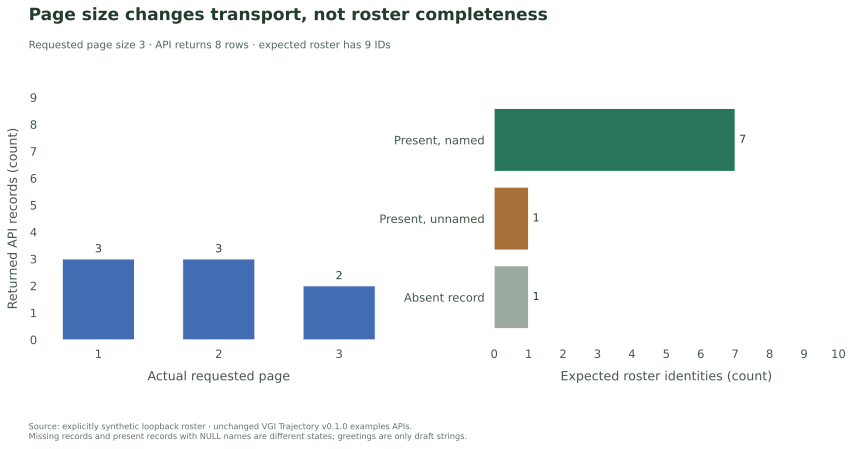

In [15]:
example.roster_accounting(pages, outcomes, PAGE_SIZE)


### Check both populations and the request trail

The checks below verify the authored fixture, join and greeting semantics. They also require a single consecutive page traversal, the requested page size, eight returned records, and a terminal null `next_page`. An authorization header would make the fixture reject the request. These checks establish this bounded example's behavior, not the completeness or reliability of another API.


In [16]:
%%sql checks <<
SELECT 'eight unique API records' AS check_name, count(*)=8 AND count(DISTINCT id)=8 AS passed FROM api_items
UNION ALL SELECT 'nine independently expected identities', count(*)=9 AND min(expected_id)=1 AND max(expected_id)=9 FROM expected_roster
UNION ALL SELECT 'no unexpected API identities', count(*)=0 FROM api_items a ANTI JOIN expected_roster e ON a.id=e.expected_id
UNION ALL SELECT 'missing ID 6 retained', count(*)=1 AND min(expected_id)=6 FROM reconciled WHERE api_id IS NULL
UNION ALL SELECT 'present ID 4 has NULL name', count(*)=1 AND min(expected_id)=4 FROM reconciled WHERE api_id IS NOT NULL AND name IS NULL
UNION ALL SELECT 'both tones preserve names', count(*)=7 AND bool_and(casual_draft='Hi, '||name||'!' AND formal_draft='Good day, '||name||'.') FROM reconciled WHERE name IS NOT NULL
UNION ALL SELECT 'missing names yield no drafts', count(*)=2 AND bool_and(casual_draft IS NULL AND formal_draft IS NULL) FROM reconciled WHERE name IS NULL
UNION ALL SELECT 'one consecutive page traversal', count(*)=ceil(8.0/{{ PAGE_SIZE }}) AND count(DISTINCT page)=count(*) AND min(page)=1 AND max(page)=count(*) AND bool_and(page=request_index) FROM request_log
UNION ALL SELECT 'requested page size respected', bool_and(page_size={{ PAGE_SIZE }} AND returned_rows BETWEEN 1 AND {{ PAGE_SIZE }}) FROM request_log
UNION ALL SELECT 'all requests succeeded without auth', bool_and(status=200 AND NOT authorization_present) FROM request_log
UNION ALL SELECT 'page rows account for complete source', sum(returned_rows)=8 FROM request_log
UNION ALL SELECT 'terminal next_page only on last request', count(*) FILTER(WHERE next_page IS NULL)=1 AND bool_and(CASE WHEN page=ceil(8.0/{{ PAGE_SIZE }}) THEN next_page IS NULL ELSE next_page=page+1 END) FROM request_log;


In [17]:
display(checks)
assert len(checks) == 12 and checks.passed.eq(True).all()
prose(f"**All {len(checks)} checks passed.** The page audit and the expected-identity audit reconcile separately.")


,check_name,passed
0,eight unique API records,True
1,nine independently expected identities,True
2,no unexpected API identities,True
3,missing ID 6 retained,True
4,present ID 4 has NULL name,True
5,both tones preserve names,True
6,missing names yield no drafts,True
7,one consecutive page traversal,True
8,requested page size respected,True
9,all requests succeeded without auth,True


**All 12 checks passed.** The page audit and the expected-identity audit reconcile separately.

### Try five records per page

Change only `PAGE_SIZE` to **5** and Run All. The eight-record source fingerprint, nine expected identities, missing ID, unnamed ID and greeting drafts should remain identical; the request trail and left panel should change. Compare those invariants before attributing a difference to pagination. This fixture has a stable snapshot; a changing live API would need its own snapshot or consistency guarantees.

The first notebook asks what can be inferred between GPS fixes. This one asks what can be inferred from a complete paged response. In both, the observed population and the expected population must stay explicit.


In [18]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
try:
    session.close()
finally:
    fixture.close()


<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-trajectory](https://github.com/Query-farm/vgi-trajectory)
